# 08 · Robustness checks and the Phase 2 scorecard

**FinGuard AI, Phase 2.** Reads `artifacts/phase2/`.

1. **New vs known proxy entities.** Test transactions grouped by what the training window
   contained. Entities never seen in training measure detection; entities that already
   had a fraud label measure partly recognition (Phase 1 leakage finding).
2. **Label delay.** The same model trained without the 30 days before validation (labels
   not yet arrived).
3. **Ablation.** The same model without the eight proxy-entity features.
4. **Performance over time**, week by week after training.
5. **Scorecard** against the design-review reference, and limitations carried to Phase 3.

In [1]:
import sys, pathlib, json
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from finguard import config, phase2, split
from finguard.evaluation import figures as F
from finguard.evaluation import metrics as M
from finguard.models import dataset

pd.set_option("display.max_columns", 30, "display.width", 180)
T = config.TABLE_DIR
B = 1000
codes = phase2.selected_codes()
fs = dataset.load("main", codes)
m = fs.masks
y_te = fs.y[m["test"]].astype(int)
main, lr = phase2.load_preds(f"lgbm_{codes}"), phase2.load_preds("lr")
gap, abl = phase2.load_preds(f"gap_{codes}"), phase2.load_preds("ablation_no_entity")
for p in (lr, gap, abl):
    assert np.array_equal(p["test_idx"], main["test_idx"])
print("selected codes:", codes, "| test rows:", len(y_te))

selected codes: numeric | test rows: 85430


## 1. New vs known proxy entities
Proxy entity = card1 + addr1 + (day - D1): a heuristic grouping, **not a customer**.
Groups use the training window (days 0-120) only; labels are used for grouping the
evaluation, never as features.

,label,n,share_rows,frauds,share_frauds,prevalence,pr_auc,lo,hi,roc_auc,lift_pr_auc_over_random
0,never seen in training,48454,0.567178,1346,0.449566,0.027779,0.359987,0.332418,0.387849,0.832917,12.958982
1,"seen in training, no fraud label",27179,0.318144,37,0.012358,0.001361,0.007939,0.002375,0.039957,0.624159,5.831724
2,"seen in training, had a fraud label",662,0.007749,355,0.118570,0.536254,0.978104,0.969678,0.985734,0.969730,1.823957
3,"no entity key (card1, addr1 or D1 missing)",9135,0.106930,1256,0.419506,0.137493,0.751576,0.725732,0.775956,0.923416,5.466280


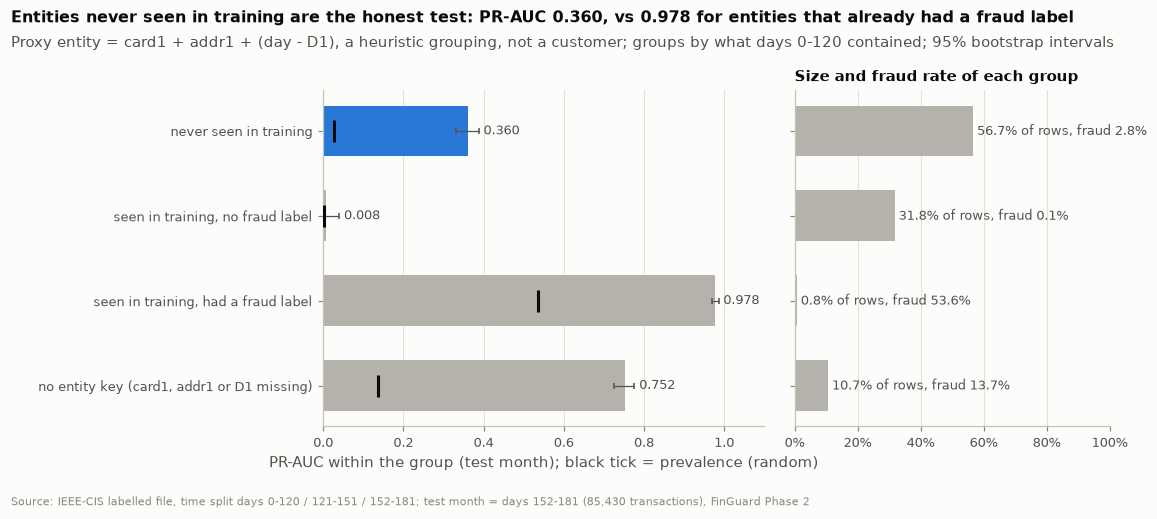

In [2]:
ent_tr = fs.entity[m["train"]]
known = set(e for e in ent_tr if e is not None)
known_fraud = set(e for e, yy in zip(ent_tr, fs.y[m["train"]]) if e is not None and yy == 1)
ent_te = fs.entity[m["test"]]
status = np.array(["no entity key (card1, addr1 or D1 missing)" if e is None else
                   "seen in training, had a fraud label" if e in known_fraud else
                   "seen in training, no fraud label" if e in known else
                   "never seen in training" for e in ent_te], dtype=object)
order = ["never seen in training", "seen in training, no fraud label", "seen in training, had a fraud label",
         "no entity key (card1, addr1 or D1 missing)"]
rows = []
for g in order:
    k = status == g
    r = M.ranking(y_te[k], main["test_raw"][k])
    lo, hi = M.bootstrap(y_te[k], main["test_raw"][k], B=500)["pr_auc"]
    rows.append({"label": g, "n": r["n"], "share_rows": k.mean(), "frauds": r["frauds"], "share_frauds": y_te[k].sum() / y_te.sum(),
                 "prevalence": r["prevalence"], "pr_auc": r["pr_auc"], "lo": lo, "hi": hi, "roc_auc": r["roc_auc"],
                 "lift_pr_auc_over_random": r["pr_auc"] / r["prevalence"]})
ent_t = pd.DataFrame(rows)
ent_t.to_csv(T / "phase2_entity_groups.csv", index=False)
fig = F.fig22_entity_groups(ent_t)
ent_t

PR-AUC depends on prevalence, so the lift over random (PR-AUC / prevalence) is shown too.
A second view that removes the prevalence effect: the share of **all** test frauds that
the global top 1% and top 5% catch, per group.

In [3]:
order_all = np.argsort(-main["test_raw"], kind="stable")
caught = {}
for k in (0.01, 0.05):
    flag = np.zeros(len(y_te), bool)
    flag[order_all[: int(round(k * len(y_te)))]] = True
    caught[f"recall in global top {k:.0%}"] = pd.Series({g: (flag & (status == g) & (y_te == 1)).sum() / max(((status == g) & (y_te == 1)).sum(), 1) for g in order})
pd.DataFrame(caught)

,recall in global top 1%,recall in global top 5%
never seen in training,0.140416,0.432392
"seen in training, no fraud label",0.000000,0.027027
"seen in training, had a fraud label",0.146479,0.802817
"no entity key (card1, addr1 or D1 missing)",0.414809,0.796178


## 2. Label delay and 3. ablation without proxy-entity features
Both are scored on the same test transactions as the main model, so a paired bootstrap
gives the difference with its interval.

,label,pr_auc,lo,hi,roc_auc,recall@1%,recall@5%,precision@1%,main_minus_this_pr_auc,diff_ci95,share_resamples_main_not_better
0,LightGBM (main),0.580483,0.561981,0.597294,0.906831,0.254509,0.623914,0.892272,NaN,NaN,NaN
1,LightGBM without proxy-entity features,0.576358,0.558176,0.594105,0.904381,0.255845,0.621576,0.896956,0.004124,"(0.000162530132956232, 0.008227857035565295)",0.025
2,"LightGBM, label delay (train days 0-90)",0.526745,0.507928,0.544734,0.891733,0.251169,0.565464,0.880562,0.053738,"(0.045253577914712004, 0.06244909648330795)",0.000
3,Logistic regression (baseline),0.419381,0.400471,0.438296,0.852126,0.230795,0.459252,0.809133,0.161101,"(0.1474216980835722, 0.1753916395113853)",0.000


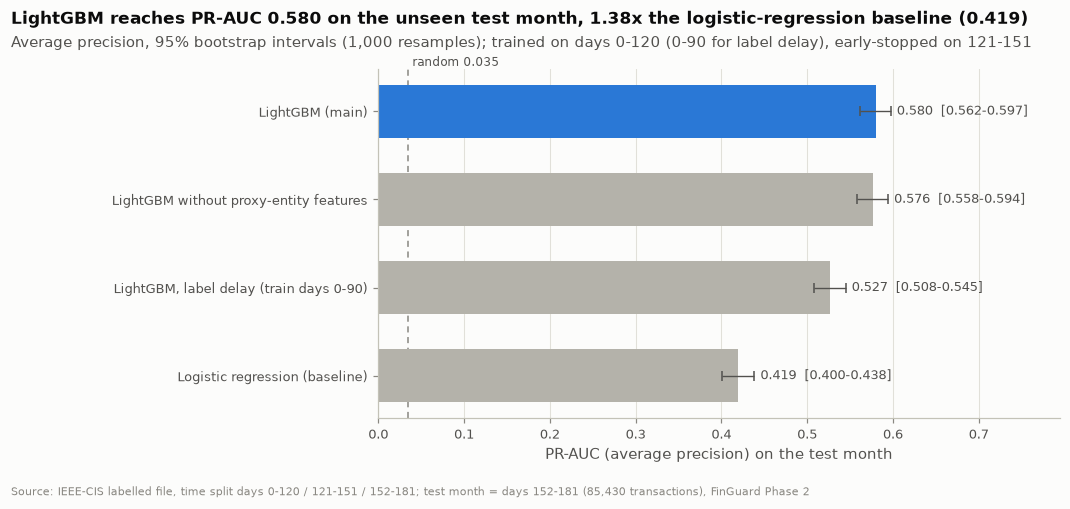

In [4]:
runs = {"LightGBM (main)": main, "LightGBM without proxy-entity features": abl,
        "LightGBM, label delay (train days 0-90)": gap, "Logistic regression (baseline)": lr}
comp_rows = []
for name, p in runs.items():
    r = M.ranking(y_te, p["test_raw"])
    ci = M.bootstrap(y_te, p["test_raw"], B=B)
    row = {"label": name, "pr_auc": r["pr_auc"], "lo": ci["pr_auc"][0], "hi": ci["pr_auc"][1], "roc_auc": r["roc_auc"],
           "recall@1%": r["recall@1%"], "recall@5%": r["recall@5%"], "precision@1%": r["precision@1%"], "highlight": name == "LightGBM (main)"}
    if name != "LightGBM (main)":
        d = M.paired_difference(y_te, main["test_raw"], p["test_raw"], B=B)
        row |= {"main_minus_this_pr_auc": d["pr_auc"]["difference"], "diff_ci95": d["pr_auc"]["ci95"],
                "share_resamples_main_not_better": d["pr_auc"]["share_resamples_not_better"]}
    comp_rows.append(row)
comp = pd.DataFrame(comp_rows)
comp.to_csv(T / "phase2_model_comparison.csv", index=False)
fig = F.fig17_model_comparison(comp, float(y_te.mean()))
comp.drop(columns="highlight")

In [5]:
info = {n: phase2.load_info(k) for n, k in [("main", f"lgbm_{codes}"), ("gap", f"gap_{codes}"), ("ablation", "ablation_no_entity")]}
pd.DataFrame({n: {"train rows": int((split.masks(fs.day, i["scheme"])["train"]).sum()), "best iteration": i["best_iteration"],
                  "features": i["n_features"], "valid PR-AUC": i["valid"]["pr_auc"], "test PR-AUC": i["test"]["pr_auc"]}
              for n, i in info.items()}).T

,train rows,best iteration,features,valid PR-AUC,test PR-AUC
main,417559.0,2638.0,473.0,0.659172,0.580483
gap,319934.0,2934.0,473.0,0.560884,0.526745
ablation,417559.0,1938.0,465.0,0.656877,0.576358


## 4. Performance week by week after training
7-day windows from the start of validation and of test (the last short window of each
period is merged into the one before). Validation weeks were used for early stopping.

,part,first_day,days,n,frauds,prevalence,pr_auc,roc_auc,recall@5%
0,valid,121,7,22459,684,0.030455,0.766063,0.954161,0.790936
1,valid,128,7,18782,767,0.040837,0.694882,0.930918,0.706649
2,valid,135,7,18597,652,0.035059,0.588127,0.922656,0.659509
3,valid,142,10,27713,845,0.030491,0.595713,0.913617,0.641420
4,test,152,7,20967,632,0.030143,0.605903,0.911661,0.645570
5,test,159,7,20802,647,0.031103,0.541561,0.900593,0.619784
6,test,166,7,20389,773,0.037913,0.554934,0.901282,0.593790
7,test,173,9,23272,942,0.040478,0.614616,0.911796,0.632696


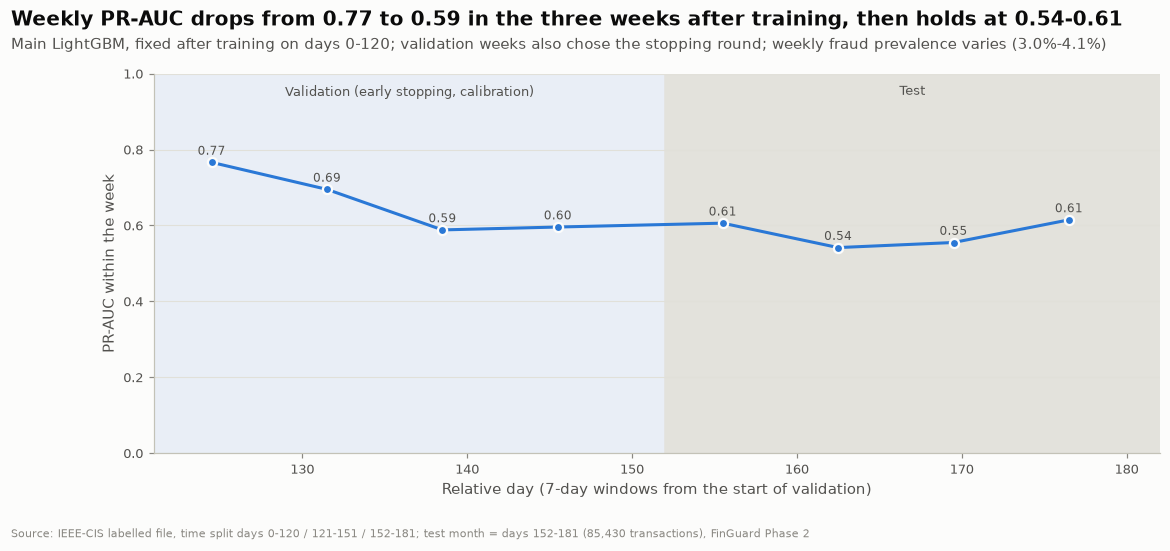

In [6]:
def weekly(part, raw):
    d0, d1 = split.SCHEMES["main"][part]
    day = fs.day[m[part]]
    n_full = (d1 - d0 + 1) // 7
    wk = np.minimum((day - d0) // 7, n_full - 1)
    rows = []
    for w in range(n_full):
        k = wk == w
        r = M.ranking(fs.y[m[part]][k], raw[k])
        rows.append({"part": part, "first_day": d0 + 7 * w, "days": int(np.unique(day[k]).size), **r})
    return rows
wk = pd.DataFrame(weekly("valid", main["valid_raw"]) + weekly("test", main["test_raw"]))
wk.to_csv(T / "phase2_weekly.csv", index=False)
fig = F.fig21_weekly(wk)
wk[["part", "first_day", "days", "n", "frauds", "prevalence", "pr_auc", "roc_auc", "recall@5%"]]

Why the first weeks score higher: right after training, more of the frauds come from proxy
entities that already had a fraud label in days 0-120 (recognition, section 1).

In [7]:
def recognisable(part):
    d0, d1 = split.SCHEMES["main"][part]
    day, ent, yy = fs.day[m[part]], fs.entity[m[part]], fs.y[m[part]]
    n_full = (d1 - d0 + 1) // 7
    w = np.minimum((day - d0) // 7, n_full - 1)
    kf = np.array([e in known_fraud for e in ent])
    return [{"part": part, "first_day": d0 + 7 * i,
             "share_of_frauds_from_entities_with_fraud_label": (kf[w == i] & (yy[w == i] == 1)).sum() / yy[w == i].sum()}
            for i in range(n_full)]
rec = pd.DataFrame(recognisable("valid") + recognisable("test"))
wk = wk.merge(rec, on=["part", "first_day"])
wk.to_csv(T / "phase2_weekly.csv", index=False)
wk[["part", "first_day", "pr_auc", "share_of_frauds_from_entities_with_fraud_label"]].round(3)

,part,first_day,pr_auc,share_of_frauds_from_entities_with_fraud_label
0,valid,121,0.766,0.287
1,valid,128,0.695,0.286
2,valid,135,0.588,0.202
3,valid,142,0.596,0.231
4,test,152,0.606,0.141
5,test,159,0.542,0.128
6,test,166,0.555,0.083
7,test,173,0.615,0.126


## 5. Scorecard against the design-review reference
The reference numbers come from the design review's exploratory run (scikit-learn
HistGradientBoosting, fewer engineered features, same time split). They are a bar to clear,
not a contract: the Phase 2 pipeline is stricter (all statistics frozen on the training
window, normalised drifting fields, D columns re-expressed). A result counts as "met" when it
is at least as good as the reference; "within 95% interval" when it is worse but the reference
lies inside the result's bootstrap or Wilson interval (the difference is not distinguishable
from noise).

In [8]:
R6 = json.loads((T / "phase2_results.json").read_text())
E7 = json.loads((T / "phase2_explanations.json").read_text())
tm, cal, ci = R6["test_metrics"], R6["calibration"], R6["bootstrap_ci95"]
band = {b["band"]: b for b in R6["bands"]["test"]}
lgb_ci, lr_ci = ci["LightGBM"], ci["Logistic regression"]
ref = [  # metric, reference, result, 95% interval or None, better
    ("PR-AUC, main model", 0.546, tm["LightGBM"]["pr_auc"], lgb_ci["pr_auc"], "higher"),
    ("PR-AUC, logistic regression", 0.445, tm["Logistic regression"]["pr_auc"], lr_ci["pr_auc"], "higher"),
    ("ROC-AUC, main model", 0.899, tm["LightGBM"]["roc_auc"], lgb_ci["roc_auc"], "higher"),
    ("Precision at top 1%", 0.902, tm["LightGBM"]["precision@1%"], lgb_ci["precision@1%"], "higher"),
    ("Recall at top 1%", 0.257, tm["LightGBM"]["recall@1%"], lgb_ci["recall@1%"], "higher"),
    ("Precision at top 5%", 0.405, tm["LightGBM"]["precision@5%"], lgb_ci["precision@5%"], "higher"),
    ("Recall at top 5%", 0.578, tm["LightGBM"]["recall@5%"], lgb_ci["recall@5%"], "higher"),
    ("ECE after isotonic calibration", 0.004, cal["LightGBM, isotonic"]["ece"], None, "lower"),
    ("High-band fraud rate (test)", 0.906, band["High"]["fraud_rate"], (band["High"]["lo"], band["High"]["hi"]), "higher"),
    ("Medium-band fraud rate (test)", 0.267, band["Medium"]["fraud_rate"], (band["Medium"]["lo"], band["Medium"]["hi"]), "higher"),
    ("Low-band fraud rate (test)", 0.015, band["Low"]["fraud_rate"], (band["Low"]["lo"], band["Low"]["hi"]), "lower"),
    ("Top-5 family overlap, 5 retrains", 0.6, E7["stability"]["mean_pairwise_overlap"], None, "higher"),
]
def verdict(r, v, iv, better):
    if (v >= r) if better == "higher" else (v <= r):
        return "met"
    if iv is not None and iv[0] <= r <= iv[1]:
        return "within 95% interval of reference"
    if iv is None and abs(v - r) <= 0.0005:
        return "equal at reported precision"
    return "below reference" if better == "higher" else "above reference"
score = pd.DataFrame([{"metric": a, "reference": r, "phase2": v,
                       "ci95": "" if iv is None else f"{iv[0]:.3f}-{iv[1]:.3f}", "better": better,
                       "status": verdict(r, v, iv, better)} for a, r, v, iv, better in ref])
brier_ok = cal["LightGBM, isotonic"]["brier"] < cal["LightGBM, uncalibrated"]["brier"]
score.loc[len(score)] = {"metric": "Brier score: calibrated below uncalibrated", "reference": cal["LightGBM, uncalibrated"]["brier"],
                         "phase2": cal["LightGBM, isotonic"]["brier"], "ci95": "", "better": "lower",
                         "status": "met" if brier_ok else "not met"}
score.to_csv(T / "phase2_scorecard.csv", index=False)
print(score.status.value_counts().to_dict())
score

{'met': 8, 'within 95% interval of reference': 3, 'below reference': 1, 'equal at reported precision': 1}


,metric,reference,phase2,ci95,better,status
0,"PR-AUC, main model",0.546000,0.580483,0.562-0.597,higher,met
1,"PR-AUC, logistic regression",0.445000,0.419381,0.400-0.438,higher,below reference
2,"ROC-AUC, main model",0.899000,0.906831,0.900-0.913,higher,met
3,Precision at top 1%,0.902000,0.892272,0.873-0.915,higher,within 95% interval of reference
4,Recall at top 1%,0.257000,0.254509,0.245-0.264,higher,within 95% interval of reference
5,Precision at top 5%,0.405000,0.437266,0.421-0.454,higher,met
6,Recall at top 5%,0.578000,0.623914,0.609-0.641,higher,met
7,ECE after isotonic calibration,0.004000,0.004086,,lower,equal at reported precision
8,High-band fraud rate (test),0.906000,0.900504,0.878-0.919,higher,within 95% interval of reference
9,Medium-band fraud rate (test),0.267000,0.306520,0.292-0.321,higher,met


## Limitations carried to Phase 3 (must stay visible in every report and UI)

* **No customer ID.** The proxy entity is a heuristic; it can merge or split real people.
  Section 1 shows how much of the score rests on entities seen before.
* **About 96% of columns are anonymized.** Reasons for those families say "meaning not
  disclosed"; analysts can verify only the readable and engineered families.
* **Label definition** (chargeback-based, propagated to linked transactions per the host)
  cannot be checked independently; the label-delay run shows sensitivity to late labels.
* **No geography, merchant or customer attributes:** fairness across customer groups cannot
  be measured with this data.
* **One time period, one fixed model.** Weekly performance (section 4) shows the decay that
  Phase 3 monitoring must watch; alert volume per band is the first drift alarm.